# 06. Sobel gradient

Gradient magnitude minus its local average: strong edges that the normal weave does not have. Good for sharp-edged defects (cuts, holes, broken yarns).

Method: `filters.py` (`METHOD_NAME = "sobel"`). Evaluation: `evaluate.py`, same rules for every experiment (README section 7): threshold from `good_cal` only, false alarms on unseen `good_test` strips and on hard negatives, recall on defect tiles. Per-tile scores and the cal/test split are saved to `results/sobel/`.

In [1]:
import sys, importlib

sys.path.insert(0, "../src/methods")
import filters as F    # all filters and methods
import evaluate as E   # shared evaluation (README section 7)
importlib.reload(F); importlib.reload(E)  # pick up edits without restarting the kernel

# ---- evaluation settings (same for every experiment) ----------------------
FABRIC = "02"           # fabric code = third part of the file name
METHOD_NAME = "sobel"  # results go to results/<METHOD_NAME>/
THR_K = 4.0             # threshold = median + THR_K x 1.4826 x MAD of good_cal scores
MIN_AREA = 4            # damage mask: drop spots smaller than this (px); keep <= 4
SCORE_K = 25            # tile score = mean of the SCORE_K highest values of the smoothed map
SCORE_SIGMA = 2.0       # smoothing before scoring (px)
NORMALIZE = True        # score = strongest spot / the tile's own typical level (removes strip-to-strip bias)
SETTINGS = dict(thr_k=THR_K, min_area=MIN_AREA, score_k=SCORE_K, score_sigma=SCORE_SIGMA,
                normalize=NORMALIZE)

# ---- method settings -------------------------------------------------------
STEPS = F.DEFAULT_STEPS
SMOOTH = 2.0              # smoothing before the gradient (px)
BG_SIGMA = 15             # local average of the gradient energy


def method(tile):
    return F.sobel(tile, STEPS, smooth=SMOOTH, bg_sigma=BG_SIGMA)


fit = None

## Results for one fabric

In [2]:
res = E.evaluate(method, FABRIC, fit=fit, **SETTINGS)
assert res is not None, f"not enough tiles for fabric {FABRIC}"
S = E.summarize(res)
E.print_summary(res, S)
print("saved to", E.save_results(res, METHOD_NAME))

fabric 02: good_cal 140 tiles (10 strips), good_test 140 tiles (10 strips), 507 hard negatives, 38 defect tiles (0 background tiles skipped)
tile threshold 20.30   pixel threshold 20.30

                    predicted OK   predicted DAMAGED
good + hard neg.             612                  35
defect                        13                  25

false alarm rate    0.0% good_test, 6.9% hard negatives
recall              65.8%  (small <50 px: 69.6% of 23, large: 60.0% of 15)
strip level         false alarm 0.0% of 10 good strips, recall 65.8% of 38 defect strips
precision           41.7%
F1                  0.510
AUROC               0.930   (threshold-free ranking quality)
mean IoU            0.236 over all defect tiles, 0.334 over detected ones
time                2.4 ms/tile (median)
saved to C:\Users\chanupa.d\Documents\concord\fabric inspection\results\sobel


### Score distribution and ROC curve
Left: tile scores with the threshold. Right: recall vs false alarm rate for every possible threshold; the dot is the threshold chosen from good_cal. The curve uses test tiles and is for analysis only.

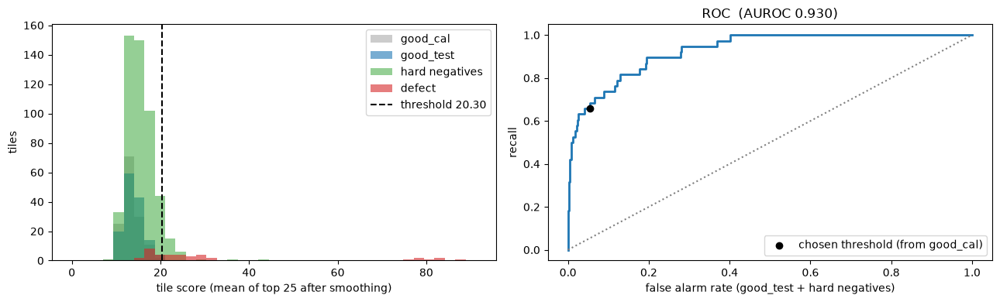

In [3]:
E.plot_scores_roc(res, S)

### Recall per defect type

In [4]:
E.print_by_type(res)

defect   tiles  found   recall  mean IoU  median area  median score
002          1      0       0%      0.02          151         19.33
006          7      7     100%      0.26         1260         79.79
019         23     16      70%      0.29           15         23.01
023          3      1      33%      0.04          778         15.64
030          4      1      25%      0.10           70         18.55


### Failure cases
Missed defects (lowest-scoring defect tiles) and false alarms (highest-scoring good_test / hard-negative tiles). Red = detected, green = ground-truth mask.

13 missed defects, 35 false alarms


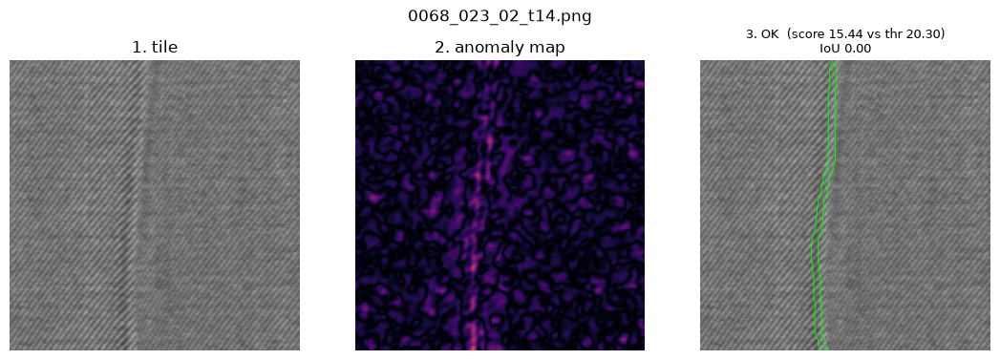

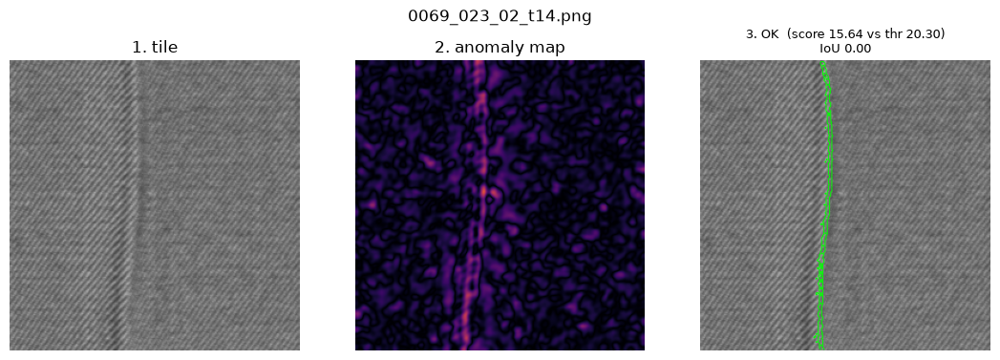

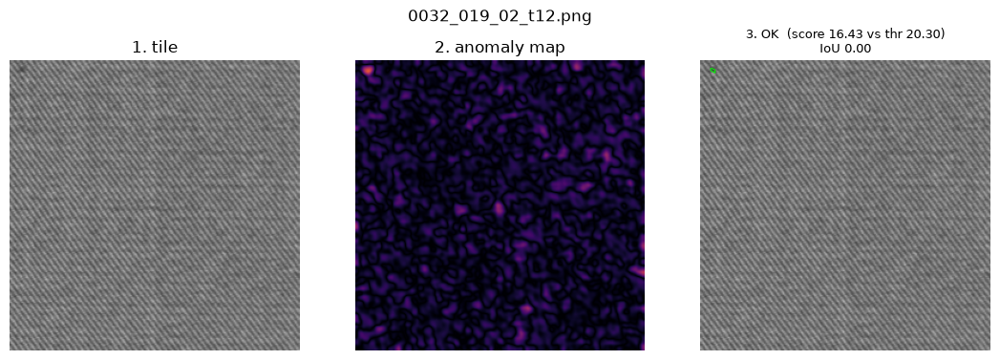

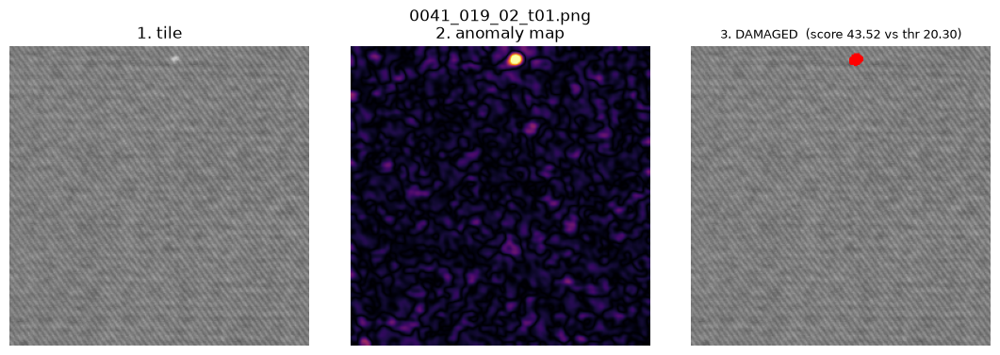

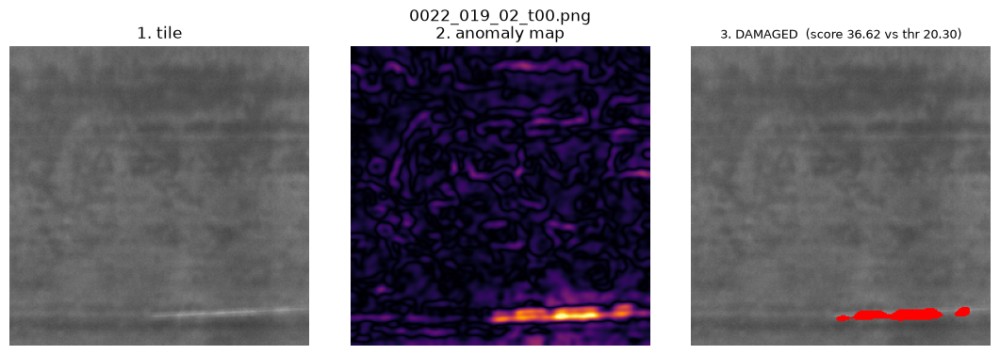

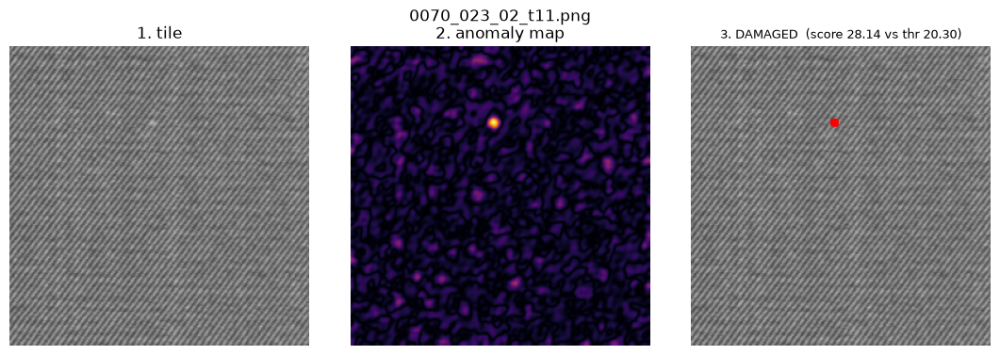

In [5]:
E.show_failures(res, n=3)

### Example tiles
Largest defect, smallest defect (by mask area) and the last good tile of `FABRIC`.

largest defect: 0016_006_02_t12.png, 2111 px


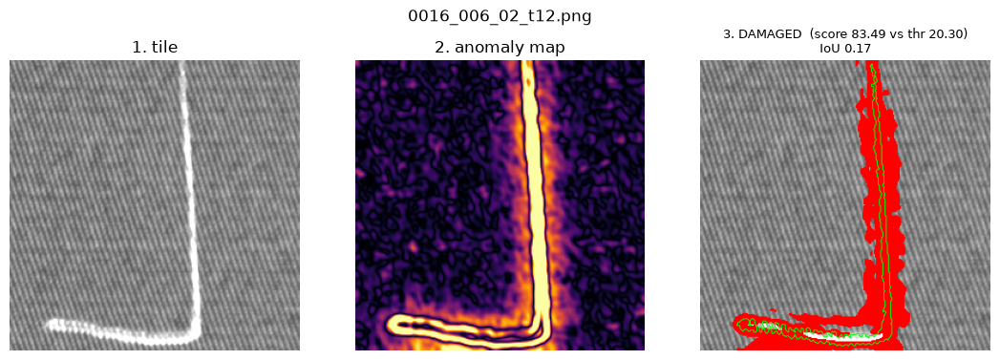

smallest defect: 0025_019_02_t10.png, 8 px


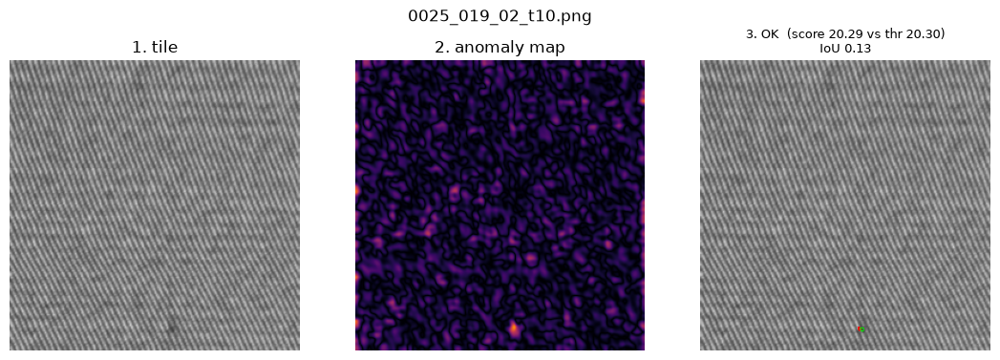

good tile: 0020_000_02_t15.png


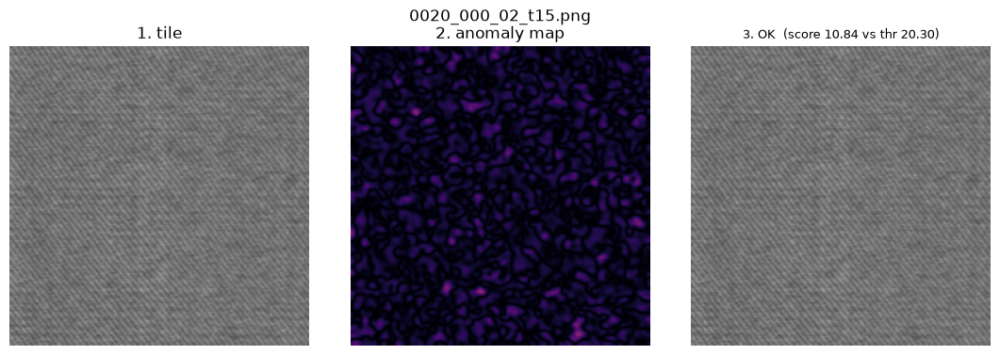

In [6]:
E.show_examples(res)

### One example per defect type
The dataset has 12 defect types (second part of the file name), spread over different fabrics. One tile per type: the clearest one (largest mask) from the fabric with the most tiles of that type. Each is judged with the threshold of its own fabric, set from that fabric's good_cal only (other fabrics are calibrated here, so this cell takes longer). Red = detected, green = ground-truth mask.

type   fabric  tiles  example tile           area px    score      thr  result
002        01     10  0005_002_01_t08.png       2514    19.49    20.02  OK (missed)
006        02      9  0016_006_02_t12.png       2111    83.49    20.30  DAMAGED (caught)
010        03     63  0103_010_03_t12.png      19060    14.43    26.34  OK (missed)
016        03      7  0021_016_03_t14.png        823    33.71    26.34  DAMAGED (caught)
019        02     40  0023_019_02_t08.png         54    17.23    20.30  OK (missed)
022        00     12  0065_022_00_t05.png        473    11.21    24.63  OK (missed)
023        01      6  0067_023_01_t09.png        577    16.65    20.02  OK (missed)
025        03      5  0107_025_03_t05.png         24    17.17    26.34  OK (missed)
027        05      1  0094_027_05_t01.png        265    26.38    19.08  DAMAGED (caught)
029        04      2  0083_029_04_t10.png        208    21.60    26.93  OK (missed)
030        03     14  0076_030_03_t09.png        222    19.22    2

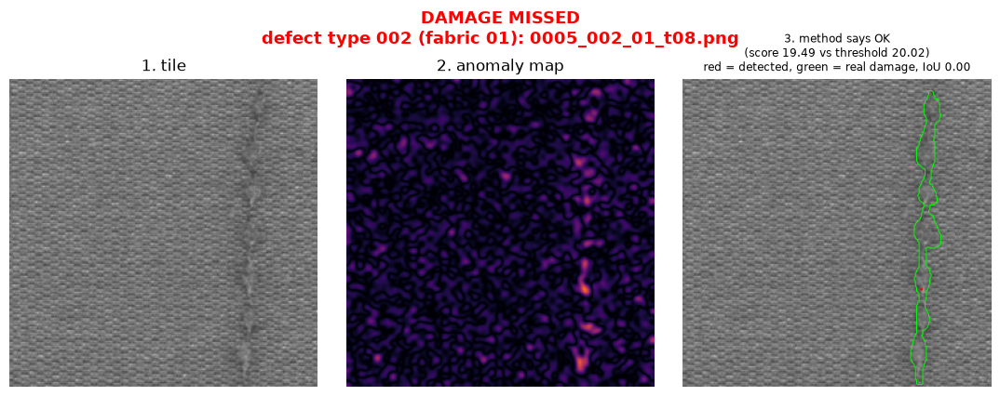

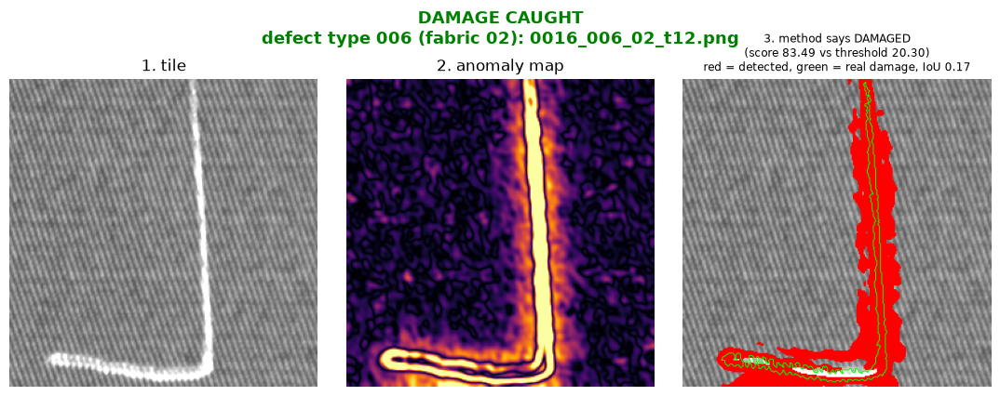

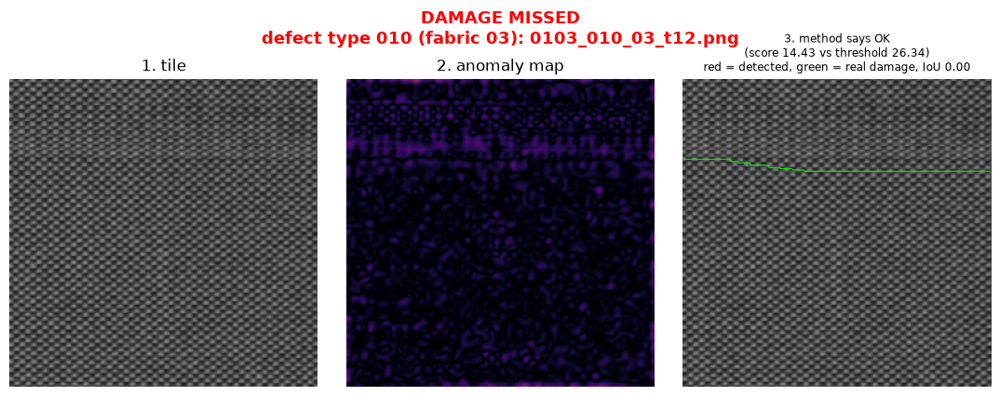

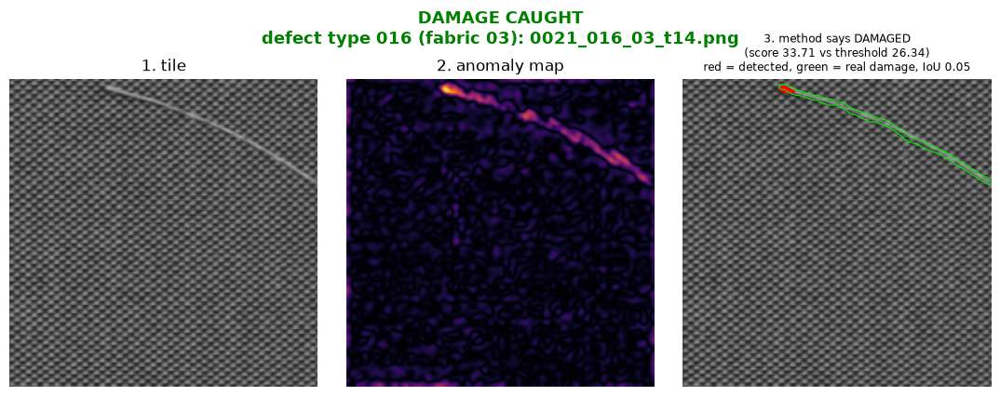

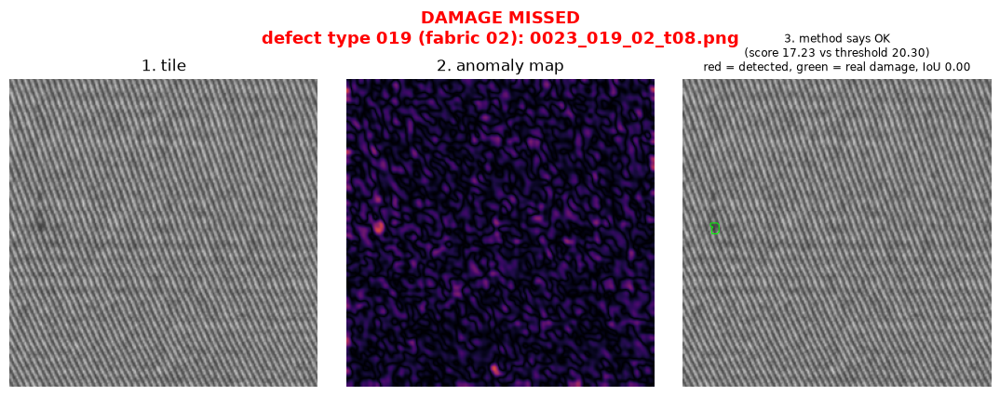

...

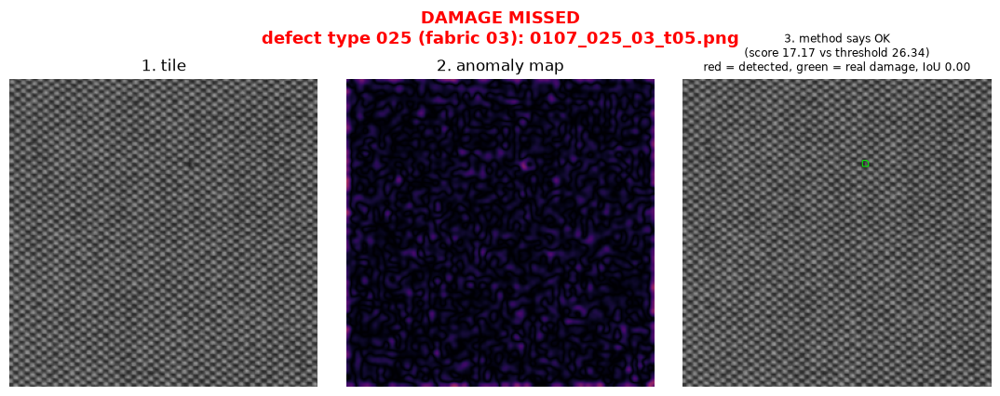

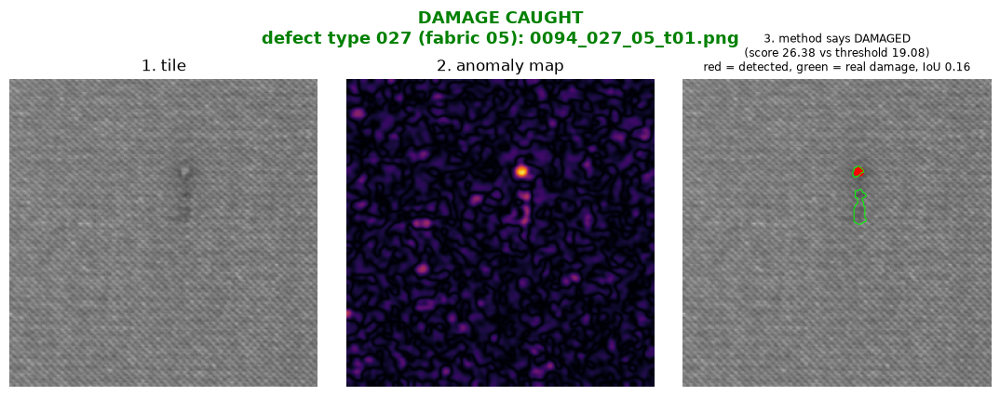

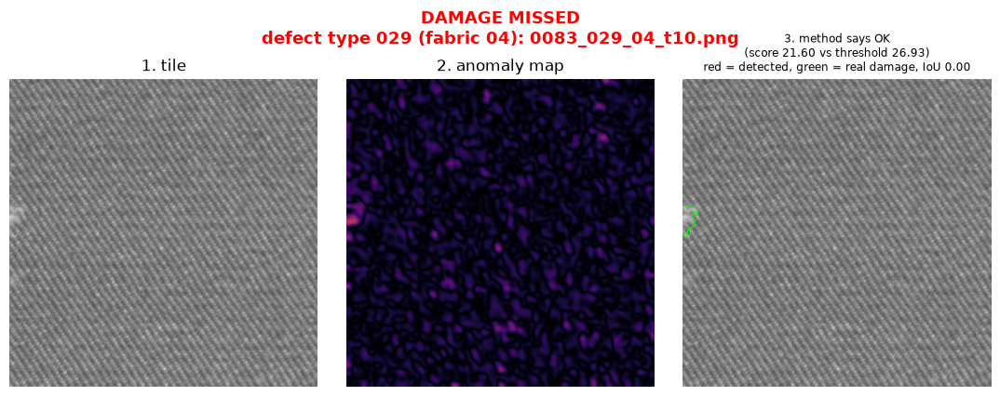

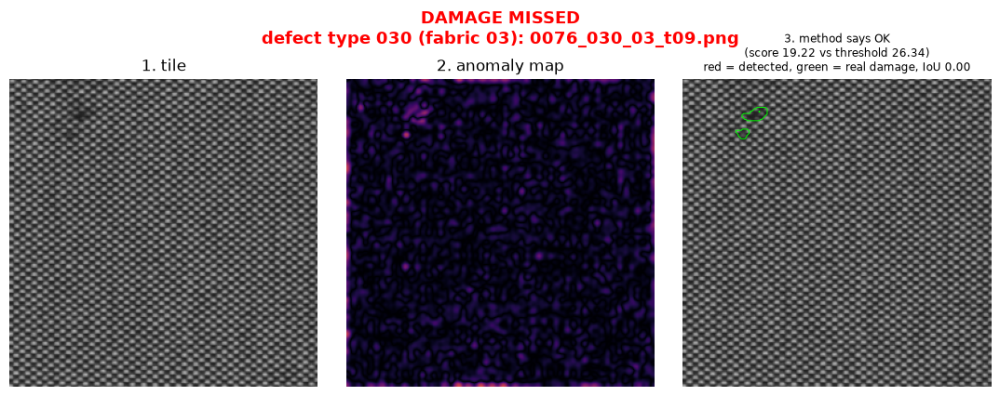

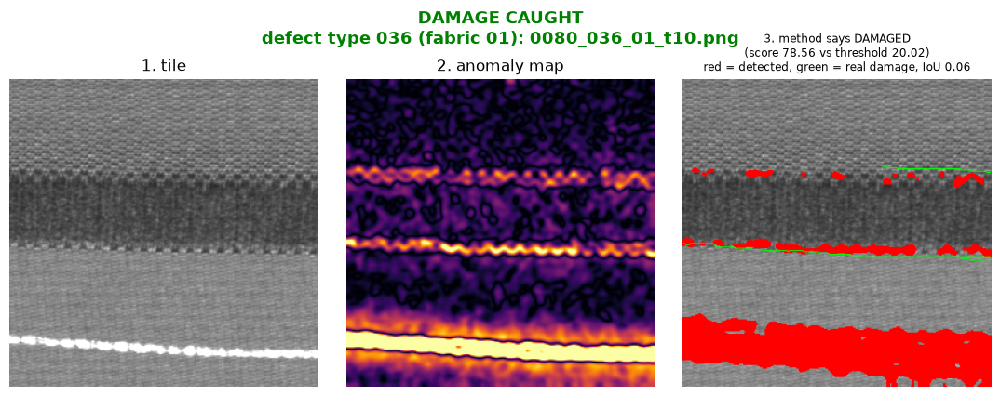

In [4]:
E.show_per_type(method, fit, res, **SETTINGS)

## All fabrics
Same method and settings on every fabric, one threshold per fabric from its own good_cal strips. Columns: FAR on good_test and on hard negatives (hn), recall overall / small / large defects, strip-level FAR and recall, AUROC, IoU, ms per tile.

In [7]:
summaries = E.all_fabrics(method, fit, METHOD_NAME, **SETTINGS)

fabric   test  hard defect    FAR  FAR hn  recall  small  large stripFAR stripRec  AUROC   IoU    ms
----------------------------------------------------------------------------------------------------
00        110    76      9   0.9%    6.6%   44.4%   0.0%  50.0%    10.0%    57.1%  0.687  0.01   1.8
01        154   146     28   1.9%    6.8%   67.9%  50.0%  69.2%    27.3%    41.7%  0.840  0.06   1.8
02        140   507     38   0.0%    6.9%   65.8%  69.6%  60.0%     0.0%    65.8%  0.930  0.24   2.5
03        110   256     89   0.0%    0.0%   22.5%   7.7%  25.0%     0.0%    36.7%  0.758  0.01   2.3
04        138   129     12   2.2%    6.2%   16.7%  20.0%  14.3%    30.0%    20.0%  0.795  0.05   2.1
05        150    13      1   2.7%    7.7%  100.0%    n/a 100.0%    20.0%   100.0%  0.988  0.16   1.9
06        143    81      7   4.9%   13.6%   71.4%  60.0% 100.0%    40.0%    83.3%  0.938  0.06   2.2
-------------------------------------------------------------------------------------------